# Assignment 7 – Evaluating the CISI Information Retrieval System
**Project (from Assignment 6):** TF-IDF + cosine-similarity search engine on the CISI collection.

**Goal:** evaluate retrieval performance with Precision, Recall, F1, MAP, nDCG (and MRR), and compare the project model against two baselines.

| Model | Description |
|---|---|
| **M1 – TF-IDF (unigram)** | baseline, single words only |
| **M2 – TF-IDF (uni+bigram)** | the model built in Assignment 6 |
| **M3 – BM25** | probabilistic ranking baseline |

Files needed in the same folder: `CISI.ALL`, `CISI.QRY`, `CISI.REL`.

## 1. Imports and settings

In [1]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

DATA_DIR = Path('.')
FIG_DIR = Path('figs'); FIG_DIR.mkdir(exist_ok=True)
K_VALUES = [1, 3, 5, 10, 20]          # cut-offs used for @k metrics
pd.set_option('display.width', 150)

## 2. Load the CISI dataset
The files use tags (`.I` id, `.T` title, `.W` text). The parser below reads each record into a dictionary.

In [2]:
def parse_tagged_file(path, text_tags):
    """Read a CISI file; return a list of records {'id':..., 'T':..., 'W':...}."""
    records, current, active_tag = [], None, None
    with open(path, 'r', encoding='latin-1') as f:
        for line in f:
            line = line.rstrip('\n')
            m = re.match(r'^\.(\w+)\s*(.*)$', line)
            if m:
                tag, rest = m.group(1), m.group(2)
                if tag == 'I':                       # a new record starts
                    if current: records.append(current)
                    current, active_tag = {'id': rest.strip()}, None
                elif current is not None and tag in text_tags:
                    current.setdefault(tag, [])
                    if rest.strip(): current[tag].append(rest.strip())
                    active_tag = tag
                else:
                    active_tag = None                 # ignore other tags (.A, .B, .X ...)
            elif current is not None and active_tag and line.strip():
                current[active_tag].append(line.strip())
    if current: records.append(current)
    for r in records:                                 # join lines into one string
        for k, v in r.items():
            if isinstance(v, list): r[k] = ' '.join(v)
    return records

raw_docs = parse_tagged_file(DATA_DIR / 'CISI.ALL', {'T', 'W'})
raw_qry  = parse_tagged_file(DATA_DIR / 'CISI.QRY', {'W'})

docs = pd.DataFrame([{'doc_id': int(r['id']), 'title': r.get('T', ''),
                      'text': (r.get('T', '') + ' ' + r.get('W', '')).strip()} for r in raw_docs])
queries = pd.DataFrame([{'query_id': int(r['id']), 'query': r.get('W', '')} for r in raw_qry])

print('Documents:', len(docs), '| Queries:', len(queries))
docs.head(3)

Documents: 1460 | Queries: 112


,doc_id,title,text
0,1,18 Editions of the Dewey Decimal Classifications,18 Editions of the Dewey Decimal Classificatio...
1,2,Use Made of Technical Libraries,Use Made of Technical Libraries This report is...
2,3,Two Kinds of Power An Essay on Bibliographic C...,Two Kinds of Power An Essay on Bibliographic C...


## 3. Load relevance judgments
Each line of `CISI.REL` is `query_id  doc_id  0  0.0`. Every listed pair is treated as **relevant (binary relevance)**; all other documents are non-relevant.

In [3]:
rel_rows = []
with open(DATA_DIR / 'CISI.REL', encoding='latin-1') as f:
    for line in f:
        p = line.split()
        if len(p) >= 2:
            rel_rows.append((int(p[0]), int(p[1])))
rel = pd.DataFrame(rel_rows, columns=['query_id', 'doc_id']).drop_duplicates()

# dictionary: query_id -> set of relevant doc ids
relevant = rel.groupby('query_id')['doc_id'].apply(set).to_dict()

print('Relevance pairs:', len(rel))
print('Queries with judgments:', len(relevant), 'of', len(queries))
print('Avg relevant docs per query: %.1f' % np.mean([len(s) for s in relevant.values()]))

Relevance pairs: 3114
Queries with judgments: 76 of 112
Avg relevant docs per query: 41.0


## 4. Retrieval models
Each model has a `rank(query)` function that returns **all** document ids sorted from best to worst score (documents with score 0 are dropped).

In [4]:
doc_ids = docs['doc_id'].to_numpy()

class TfidfModel:
    """TF-IDF vectors + cosine similarity."""
    def __init__(self, name, ngram_range):
        self.name = name
        self.vec = TfidfVectorizer(lowercase=True, stop_words='english',
                                   ngram_range=ngram_range, max_df=0.95, sublinear_tf=True)
        self.matrix = self.vec.fit_transform(docs['text'])
    def scores(self, q):
        return cosine_similarity(self.vec.transform([q]), self.matrix).ravel()

class BM25Model:
    """Okapi BM25 (k1=1.5, b=0.75)."""
    def __init__(self, name, k1=1.5, b=0.75):
        self.name, self.k1, self.b = name, k1, b
        self.vec = CountVectorizer(lowercase=True, stop_words='english')
        self.tf = self.vec.fit_transform(docs['text']).tocsc().astype(float)
        N = self.tf.shape[0]
        df = np.asarray((self.tf > 0).sum(axis=0)).ravel()
        self.idf = np.log(1 + (N - df + 0.5) / (df + 0.5))
        self.dl = np.asarray(self.tf.sum(axis=1)).ravel()
        self.avgdl = self.dl.mean()
    def scores(self, q):
        s = np.zeros(self.tf.shape[0])
        for t in set(self.vec.build_analyzer()(q)):
            j = self.vec.vocabulary_.get(t)
            if j is None: continue
            col = self.tf[:, j].toarray().ravel()
            denom = col + self.k1 * (1 - self.b + self.b * self.dl / self.avgdl)
            s += self.idf[j] * col * (self.k1 + 1) / denom
        return s

def rank(model, q):
    """Return doc ids ordered by decreasing score (score > 0 only)."""
    s = model.scores(q)
    order = np.argsort(-s, kind='stable')
    return [int(doc_ids[i]) for i in order if s[i] > 0]

models = [TfidfModel('M1 TF-IDF (unigram)', (1, 1)),
          TfidfModel('M2 TF-IDF (uni+bigram)', (1, 2)),
          BM25Model('M3 BM25')]
for m in models: print('built', m.name)

built M1 TF-IDF (unigram)
built M2 TF-IDF (uni+bigram)
built M3 BM25


## 5. Evaluation metrics
For one query, with ranked list *R* and relevant set *Rel*:

* **Precision@k** = relevant in top-k / k
* **Recall@k** = relevant in top-k / |Rel|
* **F1@k** = harmonic mean of the two
* **Average Precision (AP)** = mean of precision at every rank where a relevant document appears (over the whole ranking); **MAP** = mean AP over queries
* **nDCG@k** = DCG@k / ideal DCG@k with binary gain and log2 discount
* **Reciprocal Rank (RR)** = 1 / rank of first relevant doc; **MRR** = mean RR

In [5]:
def precision_at_k(ranked, rel_set, k):
    return sum(d in rel_set for d in ranked[:k]) / k

def recall_at_k(ranked, rel_set, k):
    return sum(d in rel_set for d in ranked[:k]) / len(rel_set)

def f1_at_k(ranked, rel_set, k):
    p, r = precision_at_k(ranked, rel_set, k), recall_at_k(ranked, rel_set, k)
    return 2 * p * r / (p + r) if p + r else 0.0

def average_precision(ranked, rel_set):
    hits, total = 0, 0.0
    for rank_, d in enumerate(ranked, start=1):
        if d in rel_set:
            hits += 1
            total += hits / rank_
    return total / len(rel_set)

def ndcg_at_k(ranked, rel_set, k):
    dcg = sum(1 / np.log2(i + 2) for i, d in enumerate(ranked[:k]) if d in rel_set)
    idcg = sum(1 / np.log2(i + 2) for i in range(min(len(rel_set), k)))
    return dcg / idcg

def reciprocal_rank(ranked, rel_set):
    for rank_, d in enumerate(ranked, start=1):
        if d in rel_set: return 1 / rank_
    return 0.0

def eleven_point_pr(ranked, rel_set):
    """Interpolated precision at recall levels 0.0, 0.1 ... 1.0."""
    hits, pts = 0, []
    for rank_, d in enumerate(ranked, start=1):
        if d in rel_set:
            hits += 1
            pts.append((hits / len(rel_set), hits / rank_))
    return [max([p for r, p in pts if r >= lvl], default=0.0) for lvl in np.linspace(0, 1, 11)]

# quick sanity check on a toy example: relevant = {1,3}, ranking = [1,2,3,4]
print('P@2  =', precision_at_k([1,2,3,4], {1,3}, 2), '(expected 0.5)')
print('AP   =', average_precision([1,2,3,4], {1,3}), '(expected (1/1 + 2/3)/2 = 0.8333)')
print('nDCG@3 = %.4f' % ndcg_at_k([1,2,3,4], {1,3}, 3), '(expected 0.9197)')

P@2  = 0.5 (expected 0.5)
AP   = 0.8333333333333333 (expected (1/1 + 2/3)/2 = 0.8333)
nDCG@3 = 0.9197 (expected 0.9197)


## 6. Run all models on all judged queries

In [6]:
eval_q = queries[queries['query_id'].isin(relevant)]     # only queries that have judgments
per_query, pr_curves = [], {m.name: [] for m in models}

for m in models:
    for q in eval_q.itertuples():
        ranked, rs = rank(m, q.query), relevant[q.query_id]
        row = {'model': m.name, 'query_id': q.query_id, 'n_relevant': len(rs),
               'AP': average_precision(ranked, rs), 'RR': reciprocal_rank(ranked, rs)}
        for k in K_VALUES:
            row[f'P@{k}']    = precision_at_k(ranked, rs, k)
            row[f'R@{k}']    = recall_at_k(ranked, rs, k)
            row[f'F1@{k}']   = f1_at_k(ranked, rs, k)
            row[f'nDCG@{k}'] = ndcg_at_k(ranked, rs, k)
        per_query.append(row)
        pr_curves[m.name].append(eleven_point_pr(ranked, rs))

pq = pd.DataFrame(per_query)
print('Evaluated queries:', eval_q.shape[0])
pq.head()

Evaluated queries: 76


,model,query_id,n_relevant,AP,RR,P@1,R@1,F1@1,nDCG@1,P@3,...,F1@5,nDCG@5,P@10,R@10,F1@10,nDCG@10,P@20,R@20,F1@20,nDCG@20
0,M1 TF-IDF (unigram),1,46,0.318424,1.000000,1.0,0.021739,0.042553,1.0,0.666667,...,0.156863,0.830420,0.5,0.108696,0.178571,0.602506,0.50,0.217391,0.303030,0.568891
1,M1 TF-IDF (unigram),2,26,0.031533,0.017241,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.00,0.000000,0.000000,0.000000
2,M1 TF-IDF (unigram),3,44,0.238113,1.000000,1.0,0.022727,0.044444,1.0,0.333333,...,0.081633,0.485229,0.5,0.113636,0.185185,0.526330,0.40,0.181818,0.250000,0.449469
3,M1 TF-IDF (unigram),4,8,0.104162,0.166667,0.0,0.000000,0.000000,0.0,0.000000,...,0.000000,0.000000,0.2,0.250000,0.222222,0.169895,0.15,0.375000,0.214286,0.227482
4,M1 TF-IDF (unigram),5,24,0.058415,0.200000,0.0,0.000000,0.000000,0.0,0.000000,...,0.068966,0.131205,0.1,0.041667,0.058824,0.085143,0.10,0.083333,0.090909,0.094570


## 7. Results
### 7.1 Summary table (mean over all queries, k = 10)

In [7]:
summary = pq.groupby('model').agg(**{
    'Precision@10': ('P@10', 'mean'), 'Recall@10': ('R@10', 'mean'),
    'F1@10': ('F1@10', 'mean'), 'nDCG@10': ('nDCG@10', 'mean'),
    'MAP': ('AP', 'mean'), 'MRR': ('RR', 'mean')}).round(4)
summary.to_csv('cisi_model_comparison.csv')
summary

,Precision@10,Recall@10,F1@10,nDCG@10,MAP,MRR
model,,,,,,
M1 TF-IDF (unigram),0.3171,0.1326,0.1546,0.3668,0.2008,0.6546
M2 TF-IDF (uni+bigram),0.3013,0.1269,0.1458,0.3358,0.1911,0.5924
M3 BM25,0.2737,0.0997,0.1184,0.3079,0.1620,0.5684


### 7.2 Metrics at different cut-offs for the project model (M2)

In [13]:
m2 = pq[pq['model'] == 'M2 TF-IDF (uni+bigram)']
cut = pd.DataFrame({k: {'Precision': m2[f'P@{k}'].mean(), 'Recall': m2[f'R@{k}'].mean(),
                        'F1': m2[f'F1@{k}'].mean(), 'nDCG': m2[f'nDCG@{k}'].mean()}
                    for k in K_VALUES}).T.round(4)
cut.index.name = 'k'
cut

,Precision,Recall,F1,nDCG
k,,,,
1,0.4605,0.0226,0.0418,0.4605
3,0.3684,0.0498,0.0823,0.3900
5,0.3395,0.0728,0.1088,0.3633
10,0.3013,0.1269,0.1458,0.3358
20,0.2336,0.1804,0.1662,0.3038


### 7.3 Model comparison chart

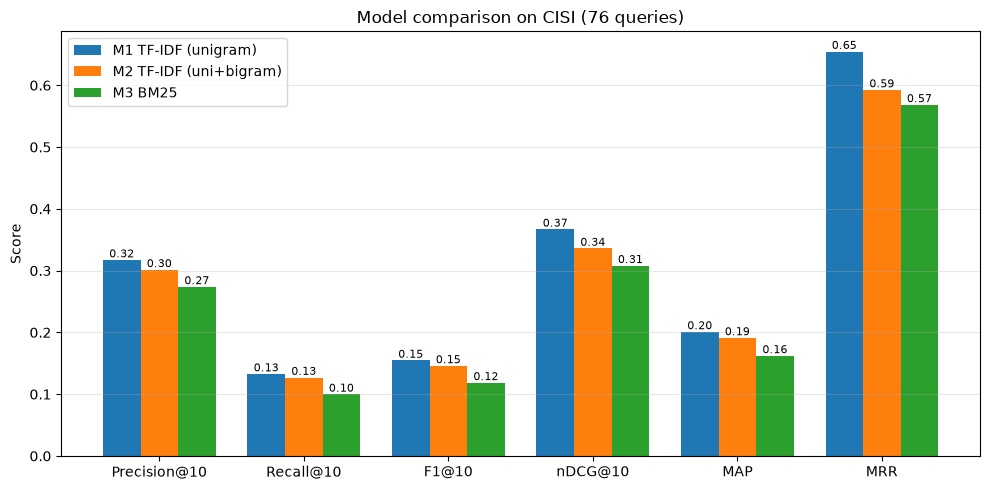

In [16]:
metrics = ['Precision@10', 'Recall@10', 'F1@10', 'nDCG@10', 'MAP', 'MRR']
x, w = np.arange(len(metrics)), 0.26
fig, ax = plt.subplots(figsize=(10, 5))
for i, (name, row) in enumerate(summary.iterrows()):
    bars = ax.bar(x + (i - 1) * w, row[metrics], w, label=name)
    ax.bar_label(bars, fmt='%.2f', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylabel('Score'); ax.set_title('Model comparison on CISI (76 queries)')
ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout()
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_DIR / 'fig1_model_comparison.png', dpi=150)
plt.show()

### 7.4 Precision / Recall / nDCG versus k (project model)

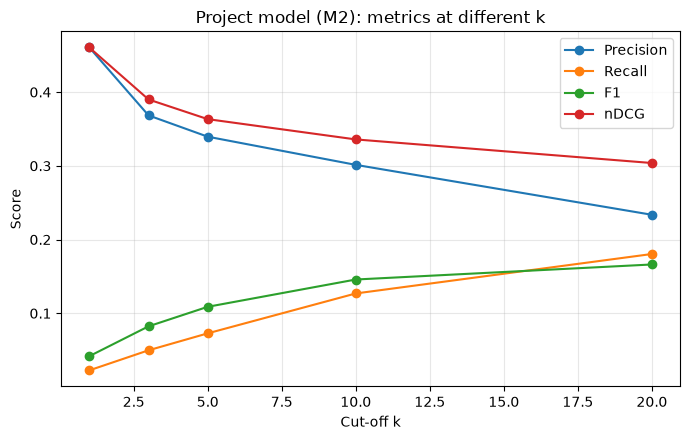

In [17]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for col in ['Precision', 'Recall', 'F1', 'nDCG']:
    ax.plot(cut.index, cut[col], marker='o', label=col)
ax.set_xlabel('Cut-off k'); ax.set_ylabel('Score')
ax.set_title('Project model (M2): metrics at different k'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig2_metrics_vs_k.png', dpi=150); plt.show()

### 7.5 Interpolated Precision–Recall curve (11-point)

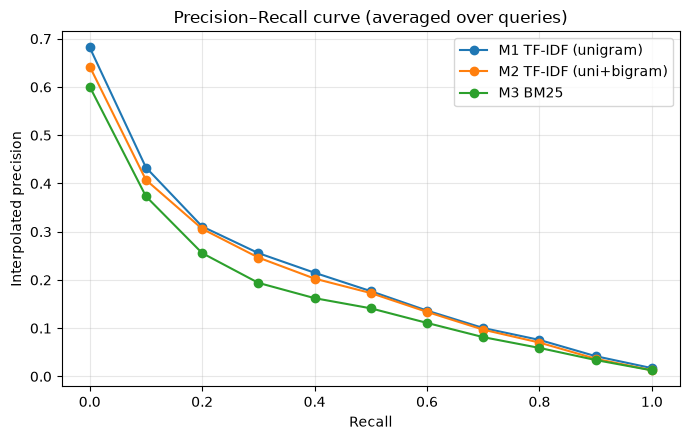

,M1 TF-IDF (unigram),M2 TF-IDF (uni+bigram),M3 BM25
0.0,0.682,0.642,0.601
0.1,0.433,0.407,0.373
0.2,0.311,0.306,0.256
0.3,0.256,0.246,0.194
0.4,0.215,0.203,0.162
0.5,0.177,0.173,0.141
0.6,0.136,0.134,0.111
0.7,0.100,0.097,0.081
0.8,0.076,0.070,0.059
0.9,0.042,0.037,0.034


In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
levels = np.linspace(0, 1, 11)
for name, curves in pr_curves.items():
    ax.plot(levels, np.mean(curves, axis=0), marker='o', label=name)
ax.set_xlabel('Recall'); ax.set_ylabel('Interpolated precision')
ax.set_title('Precision–Recall curve (averaged over queries)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig3_pr_curve.png', dpi=150); plt.show()
pd.DataFrame({n: np.mean(c, axis=0) for n, c in pr_curves.items()}, index=levels.round(1)).round(3)

### 7.6 Distribution of per-query Average Precision (project model)

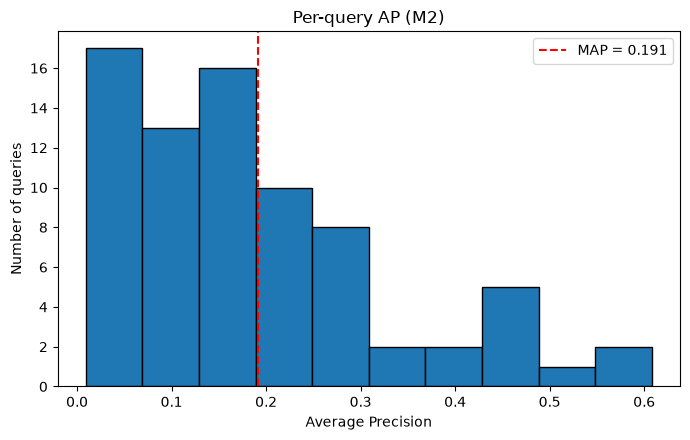

In [19]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(m2['AP'], bins=10, edgecolor='black')
ax.axvline(m2['AP'].mean(), color='red', ls='--', label='MAP = %.3f' % m2['AP'].mean())
ax.set_xlabel('Average Precision'); ax.set_ylabel('Number of queries')
ax.set_title('Per-query AP (M2)'); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR / 'fig4_ap_hist.png', dpi=150); plt.show()

### 7.7 Best and worst queries (project model)

In [20]:
qtext = queries.set_index('query_id')['query']
view = m2[['query_id', 'n_relevant', 'P@10', 'R@10', 'nDCG@10', 'AP']].copy()
view['query'] = view['query_id'].map(qtext).str.slice(0, 70)
print('TOP 5 queries by AP'); display(view.sort_values('AP', ascending=False).head(5).round(3))
print('BOTTOM 5 queries by AP'); display(view.sort_values('AP').head(5).round(3))
print('Correlation between #relevant docs and AP: %.3f' % m2['n_relevant'].corr(m2['AP']))
print('Correlation between #relevant docs and Recall@10: %.3f' % m2['n_relevant'].corr(m2['R@10']))

TOP 5 queries by AP


,query_id,n_relevant,P@10,R@10,nDCG@10,AP,query
121,52,15,0.7,0.467,0.779,0.608,What are the characteristics of MEDLARS (Medic...
128,62,12,0.5,0.417,0.633,0.581,This article concerns the problem of how to pe...
123,55,18,0.7,0.389,0.772,0.536,What are the aims and objectives of the medica...
142,96,9,0.4,0.444,0.553,0.475,Several papers have appeared that have analyze...
148,102,24,0.7,0.292,0.797,0.474,The frequency characteristics of terms in the ...


BOTTOM 5 queries by AP


,query_id,n_relevant,P@10,R@10,nDCG@10,AP,query
89,14,3,0.0,0.000,0.00,0.009,What future is there for automatic medical dia...
83,8,18,0.0,0.000,0.00,0.020,Describe information retrieval and indexing in...
92,17,26,0.1,0.038,0.11,0.025,"Means of obtaining large volume, high speed, c..."
137,82,10,0.0,0.000,0.00,0.026,The relational model has received increasing a...
77,2,26,0.0,0.000,0.00,0.032,"How can actually pertinent data, as opposed to..."


Correlation between #relevant docs and AP: 0.063
Correlation between #relevant docs and Recall@10: -0.354


### 7.8 Example search (project model)

In [21]:
q = queries.iloc[26]          # query 27
print('Query', q.query_id, ':', q.query, '\n')
ranked = rank(models[1], q.query)[:10]
ex = docs.set_index('doc_id').loc[ranked, ['title']].copy()
ex['relevant?'] = ['Yes' if d in relevant[q.query_id] else 'No' for d in ranked]
ex.index.name = 'doc_id'; ex.insert(0, 'rank', range(1, 11))
ex

Query 27 : Computerized information retrieval systems.  Computerized indexing systems. 



,rank,title,relevant?
doc_id,,,
389,1,Factors Determining the Performance of Indexin...,Yes
727,2,Evaluation of Search Time for Two Computerized...,No
827,3,The Evaluation of Information Retrieval Systems,No
1078,4,Computerized Information Retrieval Services (A...,No
1282,5,Information Retrieval Systems,No
538,6,Information Retrieval Systems,Yes
458,7,Information Retrieval Systems,No
257,8,Classification for a General Index Language,Yes
565,9,Computer Evaluation of Indexing and Text Proce...,Yes


### 7.9 Statistical check: is M2 really better than M1?
Paired t-test on per-query AP.

In [22]:
from scipy import stats
ap = pq.pivot(index='query_id', columns='model', values='AP')
for a, b in [('M2 TF-IDF (uni+bigram)', 'M1 TF-IDF (unigram)'), ('M3 BM25', 'M2 TF-IDF (uni+bigram)')]:
    t, p = stats.ttest_rel(ap[a], ap[b])
    print(f'{a}  vs  {b}:  mean diff = {ap[a].mean()-ap[b].mean():+.4f},  t = {t:.2f},  p = {p:.3f}')

M2 TF-IDF (uni+bigram)  vs  M1 TF-IDF (unigram):  mean diff = -0.0097,  t = -1.21,  p = 0.229
M3 BM25  vs  M2 TF-IDF (uni+bigram):  mean diff = -0.0291,  t = -2.90,  p = 0.005


## 8. Conclusions
Written after running the notebook – see the Word report for the full discussion. In short: the numbers in section 7.1 show how well the system ranks relevant documents, the P–R curve shows precision falling quickly as recall grows, and the per-query analysis shows that performance depends heavily on the query.